In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ziya07/network-traffic-anomaly-detection-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'network-traffic-anomaly-detection-dataset' dataset.
Path to dataset files: /kaggle/input/network-traffic-anomaly-detection-dataset


In [2]:
import pandas as pd
import numpy as np
import os
import glob
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load the dataset from kagglehub download path
# Path variable is defined in the previous cell
dataset_files = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)
if not dataset_files:
    raise FileNotFoundError("No CSV dataset file found in the kagglehub path.")

print(f"Loading dataset: {dataset_files[0]}")
df = pd.read_csv(dataset_files[0])

# 2. Define columns to drop (including labels and ports)
columns_to_drop = [col for col in df.columns if 'label' in col.lower()] + ['src_port', 'dst_port'] + ['mean_packet_size']
X_model1_new = df.drop(columns=columns_to_drop, errors='ignore')

# Identify and remove all boolean (True/False) or other non-numeric columns
boolean_cols = [col for col in X_model1_new.columns if X_model1_new[col].dtype == 'bool']
non_numeric_cols = X_model1_new.select_dtypes(exclude=[np.number]).columns.tolist()
cols_to_remove = list(set(boolean_cols + non_numeric_cols))

X_model1_new = X_model1_new.drop(columns=cols_to_remove, errors='ignore')
X_model1_new = X_model1_new.fillna(X_model1_new.median())

# 3. Scale features
scaler_m1 = StandardScaler()
X_model1_scaled = scaler_m1.fit_transform(X_model1_new)

# 4. Run K-Means
kmeans_m1 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans_m1.fit_predict(X_model1_scaled)

# 5. Display the new cluster profiles
new_m1_profiles = df.groupby('Cluster')[X_model1_new.columns].mean()
print("Updated profile means for Model 1 (without ports or boolean features):")
display(new_m1_profiles)

Loading dataset: /kaggle/input/network-traffic-anomaly-detection-dataset/embedded_system_network_security_dataset.csv
Updated profile means for Model 1 (without ports or boolean features):


,packet_size,inter_arrival_time,packet_count_5s,spectral_entropy,frequency_band_energy
Cluster,,,,,
0,0.224939,0.564396,0.475952,0.453229,0.319671
1,0.480753,0.437171,0.477465,0.575447,0.796530
2,0.766078,0.544187,0.563975,0.449188,0.310091


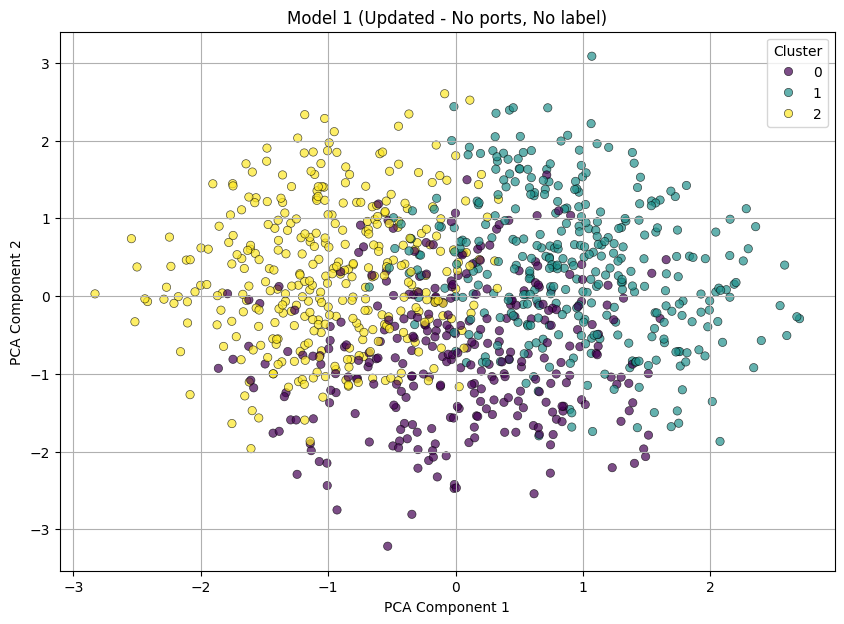

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Reduce dimensions with PCA for the new Model 1
pca_m1_new = PCA(n_components=2)
X_pca_m1_new = pca_m1_new.fit_transform(X_model1_scaled)

# 2. Create the visualization for the new Model 1
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca_m1_new[:, 0],
    y=X_pca_m1_new[:, 1],
    hue=df['Cluster'],
    palette='viridis',
    alpha=0.7,
    edgecolor='k'
)

plt.title('Model 1 (Updated - No ports, No label)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()